# Bayesian optimisation pipeline for the eight black-box functions

This notebook is the method I used each week, run from start to finish on the final data (Week 13). For each of
the eight functions it:

1. loads everything queried so far,
2. fits a Gaussian Process and a Random Forest to those points,
3. scores 10,000 random candidate points with two acquisition functions (UCB and EI),
4. proposes the next point to query.

The final query each week was chosen by hand from these proposals plus the extra searches in `scripts/`, with the
reasons recorded in `CHANGELOG.md`. The main reasoning is in the [README](../README.md), and the model's limits are in
the [model card](../model_card.md).

**How to run it.** Run the cells from top to bottom, once. The Gaussian Process fits and the random candidates share
one seeded random generator, so running a cell twice or out of order changes the candidates and therefore the picks.
It never writes to `data/`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))  # the notebook runs from notebooks/, the code lives in src/

%matplotlib inline
import pipeline
from config import FUNCTION_SETTINGS
from data_io import load_week

pipeline.setup()  # seed 42, so the 10,000 random candidates are the same on every run

## 1. Load the data

Each `data/Week_N` folder holds everything up to that week: the course's initial points first, then one row per
query I submitted. Set `WEEK` to rerun an earlier week, or leave it as `None` for the latest.

In [2]:
WEEK = None  # None = the latest week in data/
data = load_week(WEEK)
pipeline.show_shapes(data)

func1: inputs (23, 2), outputs (23,)
func2: inputs (23, 2), outputs (23,)
func3: inputs (28, 3), outputs (28,)
func4: inputs (43, 4), outputs (43,)
func5: inputs (33, 4), outputs (33,)
func6: inputs (33, 5), outputs (33,)
func7: inputs (43, 6), outputs (43,)
func8: inputs (53, 8), outputs (53,)


## 2. Best point so far

The best point for each function is reused later as the centre of the local search for F3 and F4.

In [3]:
best = pipeline.analyse(data)


func1:
  - Dimensions: 2D
  - Data points: 23
  - Output range: [-0.003606, 0.000143]
  - Best output: 0.000143
  - Best input: [0.58053  0.579941]

func2:
  - Dimensions: 2D
  - Data points: 23
  - Output range: [-0.065624, 0.741858]
  - Best output: 0.741858
  - Best input: [0.6995 0.9095]

func3:
  - Dimensions: 3D
  - Data points: 28
  - Output range: [-0.433405, -0.005410]
  - Best output: -0.005410
  - Best input: [0.401915 0.392969 0.455665]

func4:
  - Dimensions: 4D
  - Data points: 43
  - Output range: [-32.625660, 0.714132]
  - Best output: 0.714132
  - Best input: [0.361506 0.41726  0.411229 0.408367]

func5:
  - Dimensions: 4D
  - Data points: 33
  - Output range: [0.112940, 4246.414237]
  - Best output: 4246.414237
  - Best input: [0.443723 0.974215 1.       1.      ]

func6:
  - Dimensions: 5D
  - Data points: 33
  - Output range: [-2.571170, -0.057469]
  - Best output: -0.057469
  - Best input: [0.457292 0.383089 0.649005 0.785017 0.140272]

func7:
  - Dimensions: 6D
 

## 3. Model settings for each function

The kernel type and starting length scale were chosen by hand: a smooth RBF kernel for the two 2D functions, and
Matern (which allows a rougher function) for the rest, because the higher-dimensional functions have sparser data.
The fit then optimises the length scale. kappa (for UCB) and xi (for EI) started from a rule based on dimension and
were adjusted by judgement. The README has a table of the values with the reason for each.

In [4]:
print(f"{'Function':<10}{'Inputs':<8}{'Kernel':<22}{'Start length':<14}{'kappa':<8}{'xi'}")
for f, s in FUNCTION_SETTINGS.items():
    kernel = "RBF" if s["kernel"] == "rbf" else f"Matern (nu={s['nu']})"
    kernel += " + white noise" if s["white_noise"] else ""
    print(f"F{f:<9}{s['dim']:<8}{kernel:<22}{s['length_scale']:<14}{s['kappa']:<8}{s['xi']}")

Function  Inputs  Kernel                Start length  kappa   xi
F1        2       RBF + white noise     0.3           0.1     0.1
F2        2       RBF                   0.2           2.0     0.1
F3        3       Matern (nu=2.5)       0.1           1.5     0.01
F4        4       Matern (nu=2.5)       0.1           1.5     0.01
F5        4       Matern (nu=1.5)       0.2           1.5     0.01
F6        5       Matern (nu=1.5)       0.1           2.5     0.01
F7        6       Matern (nu=1.5)       0.15          1.7     0.01
F8        8       Matern (nu=1.5)       0.2           3.0     0.02


## 4. Fit the models

- **Gaussian Process (GP)** (scikit-learn). It predicts the output and how uncertain that prediction is, and it works
  well with very few points. The kernel parameters are fitted by maximising the log marginal likelihood, with 10
  random restarts.
- **Random Forest (RF)**, 200 trees. It is a second opinion: its uncertainty is the spread across the trees. From
  Week 8 I stopped choosing its picks, because it can never predict above the best value it has seen (see the model
  card).
- **F1 log-space models.** F1's outputs run from 1e-245 to 1e-3, so models fitted to the raw values cannot tell the
  points apart. Fitting log10 of the absolute output exposes the pattern. The sign is lost, so this finds the active
  region and not the exact peak.

In [5]:
models = pipeline.fit_models(data)

FITTING GP FOR EACH FUNCTION
✅ func1 fitted (2D, RBF length_scale=0.3)
✅ func1 fitted (Random Forest, 200 trees)


✅ func1 fitted (log10|y| GP and Random Forest)
✅ func2 fitted (2D, RBF length_scale=0.2)
✅ func2 fitted (Random Forest, 200 trees)


✅ func3 fitted (3D, Matern nu=2.5)
✅ func3 fitted (Random Forest, 200 trees)


✅ func4 fitted (4D, Matern nu=2.5)
✅ func4 fitted (Random Forest, 200 trees)


✅ func5 fitted (4D, Matern nu=1.5, length_scale=0.2)
✅ func5 fitted (Random Forest, 200 trees)


✅ func6 fitted (5D, Matern nu=1.5)
✅ func6 fitted (Random Forest, 200 trees)


✅ func7 fitted (6D, Matern nu=1.5, length_scale=0.15)
✅ func7 fitted (Random Forest, 200 trees)


✅ func8 fitted (8D, Matern nu=1.5, length_scale=0.2)
✅ func8 fitted (Random Forest, 200 trees)


## 5. Predict at 10,000 random candidate points

A GP prediction is cheap, so 10,000 candidates give decent coverage in 2 to 3 dimensions. It is coarse in 8
dimensions, so the picks for the higher-dimensional functions are better read as good directions than exact optima.

In [6]:
preds = pipeline.predict_candidates(data, models)

MAKING PREDICTIONS FOR EACH FUNCTION

FUNCTION 1: MAKING PREDICTIONS
Predictions for Function 1:
  Mean range: [-0.000150, -0.000150]
  Std range: [0.003234, 0.003234]
  Best predicted point: [0.00440161 0.00033016]
  Best predicted mean: -0.000150


Predictions for Function 1 (Random Forest):
  Mean range: [-0.002515, 0.000093]
  Std range: [0.000010, 0.001802]
  Best predicted point: [0.56772732 0.57931447]
  Best predicted mean: 0.000093
Predictions for Function 1 (log10|y|):
  GP mean range: [-323.003543, -1.243908]  std range: [0.334932, 38.991858]
  RF mean range: [-265.915295, -3.892355]  std range: [0.317606, 135.659865]

FUNCTION 2: MAKING PREDICTIONS
Predictions for Function 2:
  Mean range: [-0.098508, 0.735658]
  Std range: [0.001000, 0.323391]
  Best predicted point: [0.69749701 0.90750635]
  Best predicted mean: 0.735658


Predictions for Function 2 (Random Forest):
  Mean range: [-0.032961, 0.657497]
  Std range: [0.030471, 0.282258]
  Best predicted point: [0.69749701 0.90750635]
  Best predicted mean: 0.657497

FUNCTION 3: MAKING PREDICTIONS
Predictions for Function 3:
  Mean range: [-0.395621, 0.018648]
  Std range: [0.001000, 0.150139]
  Best predicted point: [0.41653349 0.46487577 0.54892202]
  Best predicted mean: 0.018648


Predictions for Function 3 (Random Forest):
  Mean range: [-0.373573, -0.010815]
  Std range: [0.005514, 0.154011]
  Best predicted point: [0.40526901 0.36600719 0.45891682]
  Best predicted mean: -0.010815

FUNCTION 4: MAKING PREDICTIONS
Predictions for Function 4:
  Mean range: [-32.609449, 0.367497]
  Std range: [0.000707, 12.583467]
  Best predicted point: [0.38455507 0.42895651 0.40975187 0.39287535]
  Best predicted mean: 0.367497


Predictions for Function 4 (Random Forest):
  Mean range: [-29.854676, 0.361490]
  Std range: [0.095338, 11.591205]
  Best predicted point: [0.38455507 0.42895651 0.40975187 0.39287535]
  Best predicted mean: 0.361490

FUNCTION 5: MAKING PREDICTIONS
Predictions for Function 5:
  Mean range: [-1.867744, 2986.934423]
  Std range: [0.001279, 316.175633]
  Best predicted point: [0.36159342 0.85802259 0.99917207 0.9956639 ]
  Best predicted mean: 2986.934423


Predictions for Function 5 (Random Forest):
  Mean range: [15.030578, 3104.760580]
  Std range: [16.068587, 1716.705035]
  Best predicted point: [0.59467149 0.877733   0.94459062 0.99266746]
  Best predicted mean: 3104.760580

FUNCTION 6: MAKING PREDICTIONS
Predictions for Function 6:
  Mean range: [-2.551077, -0.175741]
  Std range: [0.001000, 1.038308]
  Best predicted point: [0.41722807 0.35674321 0.68627497 0.69665784 0.0997485 ]
  Best predicted mean: -0.175741


Predictions for Function 6 (Random Forest):
  Mean range: [-2.331834, -0.204961]
  Std range: [0.215643, 0.804718]
  Best predicted point: [0.46658514 0.40084452 0.65543129 0.8143425  0.11787246]
  Best predicted mean: -0.204961

FUNCTION 7: MAKING PREDICTIONS
Predictions for Function 7:
  Mean range: [-0.074277, 2.216891]
  Std range: [0.001000, 0.501361]
  Best predicted point: [0.02738427 0.18621165 0.33327865 0.43806002 0.25490731 0.69857016]
  Best predicted mean: 2.216891


Predictions for Function 7 (Random Forest):
  Mean range: [0.014354, 2.579418]
  Std range: [0.022728, 0.955159]
  Best predicted point: [0.03037207 0.18013362 0.1110659  0.31411092 0.0440597  0.47916427]
  Best predicted mean: 2.579418

FUNCTION 8: MAKING PREDICTIONS
Predictions for Function 8:
  Mean range: [4.639102, 9.892758]
  Std range: [0.000999, 0.476814]
  Best predicted point: [0.29548695 0.05866899 0.09093426 0.07334936 0.95322107 0.50810207
 0.19113821 0.61691011]
  Best predicted mean: 9.892758


Predictions for Function 8 (Random Forest):
  Mean range: [6.065617, 9.905033]
  Std range: [0.025197, 1.313440]
  Best predicted point: [0.29548695 0.05866899 0.09093426 0.07334936 0.95322107 0.50810207
 0.19113821 0.61691011]
  Best predicted mean: 9.905033


## 6. What the model believes (the two 2D functions)

For each of F1 and F2, the first plot is the GP's mean prediction and the second is its uncertainty. The red star is
the best point observed so far. These plots are for inspection only and do not change the picks.


VISUALIZING FUNCTION 1 PREDICTIONS


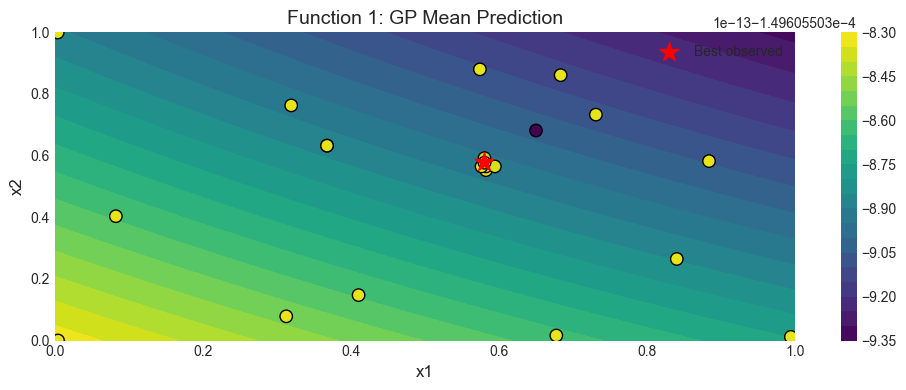

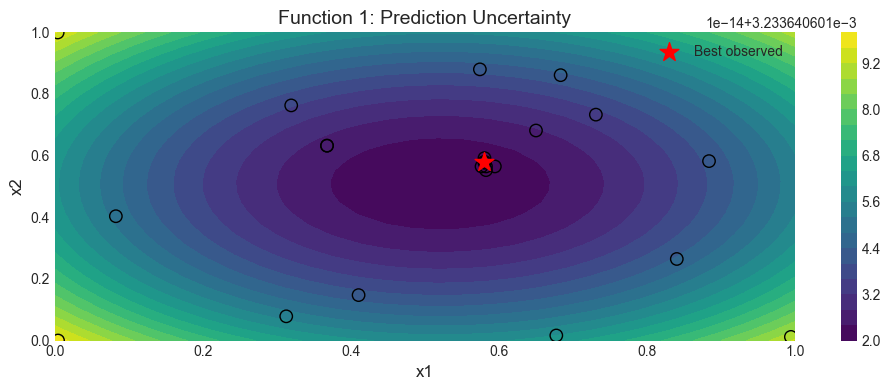


VISUALIZING FUNCTION 2 PREDICTIONS


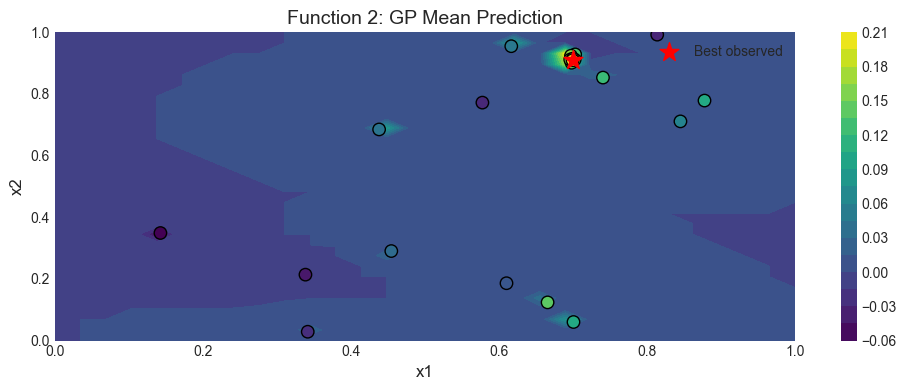

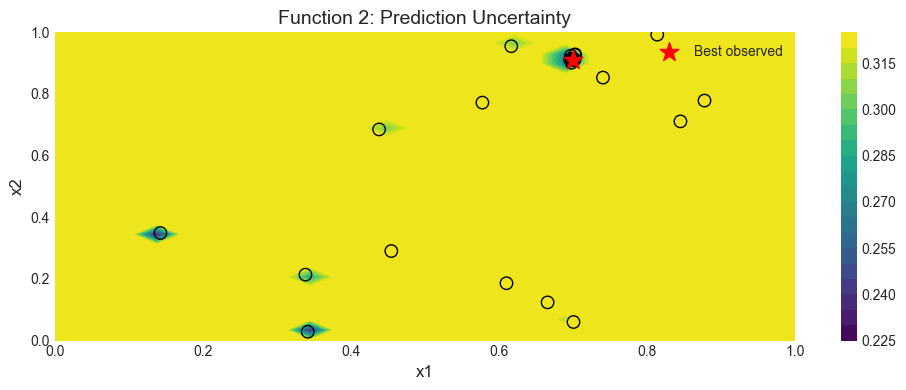

In [7]:
pipeline.plot_prediction_maps(data, models)

## 7. Choose the next point with the acquisition functions

- **UCB** (upper confidence bound) scores a point as `mean + kappa * std`. It rewards uncertainty, so it explores.
- **EI** (expected improvement) scores a point by the expected gain over the best value so far, with a margin `xi`. It
  is more cautious.

The highest score among the valid candidates is the proposed next point. When UCB and EI agree, I trust the pick more.
Any candidate within 0.001 of a point I have already queried is excluded, which I added in Week 6 after four
queries had been exact repeats. For F3 and F4 there is also a local search in a small box around the best point, and
F1 has extra log-space picks.

In [8]:
picks = pipeline.acquire(data, models, preds, best)


FUNCTION 1: ACQUISITION
UCB:
  Next point: 0.012658-0.001204
  UCB value: 0.000174
  Mean: -0.000150
  Std: 0.003234

EI (y_best=0.000143):
  Next point: 0.012658-0.001204
  EI value: 0.000000
  Mean: -0.000150
  Std: 0.003234

[Random Forest] UCB:
  Next point: 0.567727-0.579314
  UCB value: 0.000100
  Mean: 0.000093
  Std: 0.000067

[Random Forest] EI (y_best=0.000143):
  Next point: 0.642032-0.084140
  EI value: 0.000000
  Mean: -0.000833
  Std: 0.001516

[Log-space GP] UCB, best observed log10|y|=-2.442967:
  Next point: 0.645822-0.636902
  Predicted log10|y|: -1.336415  Std: 0.602111

[Log-space GP] EI:
  Next point: 0.623432-0.644396
  EI value: 1.189363
  Predicted log10|y|: -1.243908  Std: 0.422231

[Log-space RF] UCB:
  Next point: 0.632677-0.976014
  Predicted log10|y|: -66.039830  Std: 103.488117

[Log-space RF] EI:
  Next point: 0.632677-0.976014
  EI value: 17.044086
  Predicted log10|y|: -66.039830  Std: 103.488117

FUNCTION 2: ACQUISITION
UCB:
  Next point: 0.660420-0.1


[Local search ±0.04 around best] GP EI:
  Next point: 0.369611-0.432141-0.493712
  EI value: 0.011298
  Mean: -0.002284
  Std: 0.036285

[Local search ±0.04 around best] RF EI:
  Next point: 0.441829-0.399758-0.457876
  EI value: 0.002972
  Mean: -0.018962
  Std: 0.027437

FUNCTION 4: ACQUISITION
UCB:
  Next point: 0.017131-0.847027-0.959875-0.032211
  UCB value: 9.938979
  Mean: -8.244124
  Std: 12.122068

EI (y_best=0.714132):
  Next point: 0.017131-0.847027-0.959875-0.032211
  EI value: 1.618146
  Mean: -8.244124
  Std: 12.122068

[Random Forest] UCB:
  Next point: 0.363427-0.422147-0.085313-0.877577
  UCB value: 8.134337
  Mean: -5.571454
  Std: 9.137194

[Random Forest] EI (y_best=0.714132):
  Next point: 0.363427-0.422147-0.085313-0.877577
  EI value: 1.329995
  Mean: -5.571454
  Std: 9.137194



[Local search ±0.04 around best] GP EI:
  Next point: 0.359482-0.402260-0.381002-0.415601
  EI value: 0.120818
  Mean: 0.774313
  Std: 0.234607

[Local search ±0.04 around best] RF EI:
  Next point: 0.347619-0.417170-0.412664-0.437407
  EI value: 0.973242
  Mean: -0.539029
  Std: 3.815492

FUNCTION 5: ACQUISITION
UCB:
  Next point: 0.462889-0.954881-0.924400-0.939153
  UCB value: 3103.361748
  Mean: 2839.413925
  Std: 175.965215

EI (y_best=4246.414237):
  Next point: 0.462889-0.954881-0.924400-0.939153
  EI value: 0.000000
  Mean: 2839.413925
  Std: 175.965215

[Random Forest] UCB:
  Next point: 0.610737-0.970280-0.999813-0.869972
  UCB value: 4800.436897
  Mean: 2357.707722
  Std: 1628.486116

[Random Forest] EI (y_best=4246.414237):
  Next point: 0.610737-0.970280-0.999813-0.869972
  EI value: 99.154964
  Mean: 2357.707722
  Std: 1628.486116

FUNCTION 6: ACQUISITION
UCB:
  Next point: 0.022952-0.042557-0.025958-0.109314-0.024617
  UCB value: 1.791083
  Mean: -0.804687
  Std: 1.0383

## 8. Acquisition maps (the two 2D functions)

The maps use an illustrative kappa of 1.5 and xi of 0.01, not the values used for each function's pick, and the star
marks the point UCB or EI chose. For inspection only.


VISUALIZING ACQUISITION: FUNCTION 1


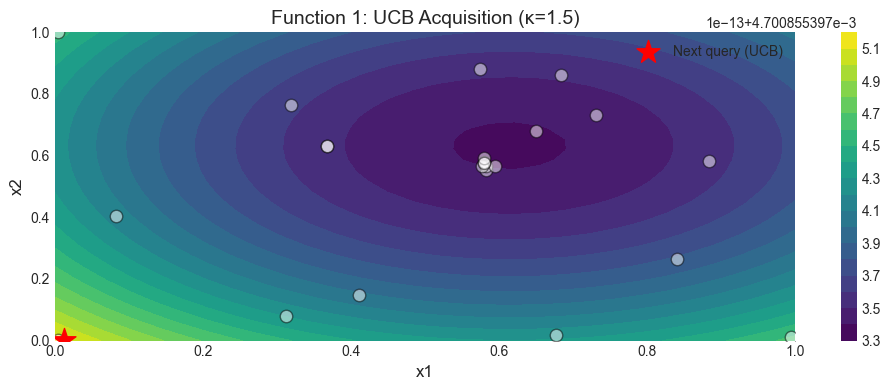

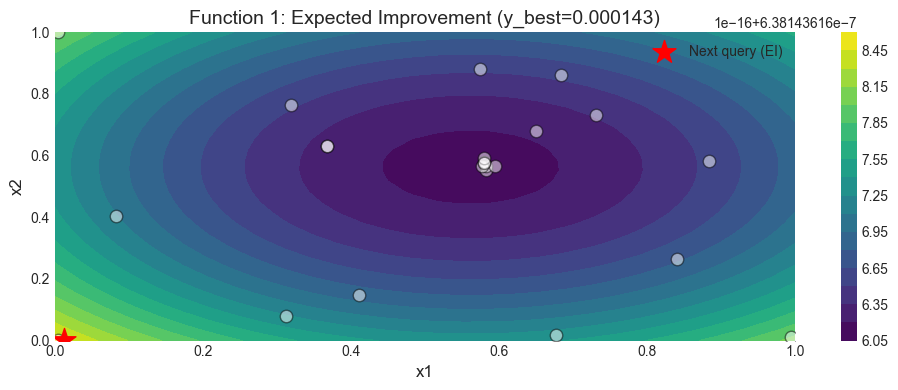


VISUALIZING ACQUISITION: FUNCTION 2


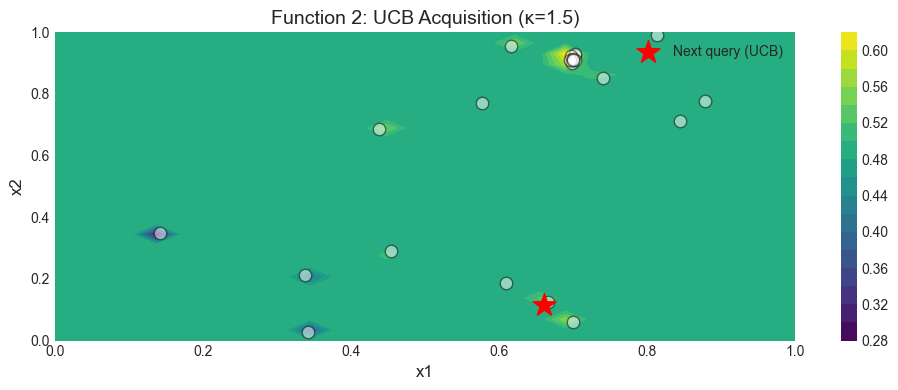

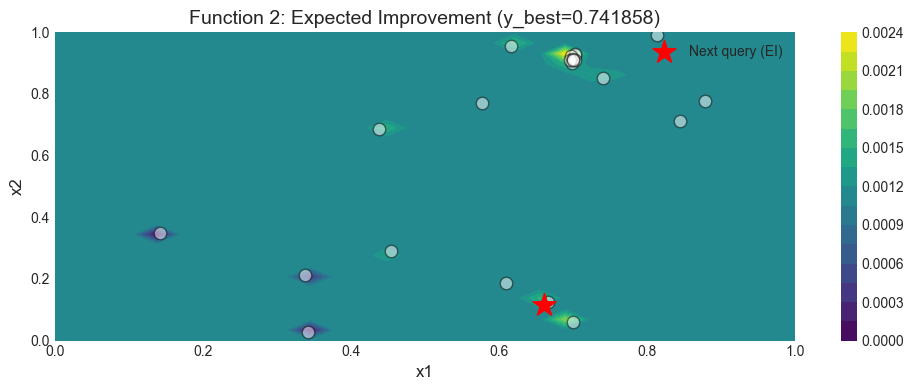

In [9]:
pipeline.plot_acquisition_maps(data, models, picks)

## 9. From proposal to weekly query

The proposals above were the starting point, not the answer. Each week I compared them with the model's track record
and chose the query by hand, often using a search that this notebook does not run: a box around the best point, line
searches and half steps, and a pattern search for F1. Those searches are in `scripts/`, and the reason for every
weekly choice is in `CHANGELOG.md`.

## 10. Adding a new week of data

Not needed for this project, which finished at Week 13, but this is how a week was added. It copies the previous
week's arrays, appends the new queries and outputs, and refuses to overwrite an existing week:

```python
import numpy as np
from data_io import append_week

queries = {1: np.array([0.58, 0.58]), ...}   # the inputs I submitted, one per function
outputs = {1: 1.2e-4, ...}                    # the outputs the course returned
append_week(14, queries, outputs)
```